# Plot GIS Variables by Resolution and Catchment

Each selected raster is rendered in its own panel for each configured resolution and catchment. Continuous, binary, and categorical variables use appropriate colorbars. Figures for ALL retain their existing filenames; other catchments are identified in the filename.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from dotenv import load_dotenv
from matplotlib.colors import BoundaryNorm, ListedColormap

load_dotenv()
krycklan_gis_data_path = os.getenv("KRYCKLAN_GIS_DATA_PATH")
if not krycklan_gis_data_path:
    raise EnvironmentError("KRYCKLAN_GIS_DATA_PATH is not set.")

figs_dir = os.path.join(krycklan_gis_data_path, "figs")
os.makedirs(figs_dir, exist_ok=True)

resos = [20, 40, 80, 160]
catchs = ["ALL", "C1", "C2"]

selected_reso = 40
plot_variables = [
    "LAI_conif",
    "LAI_decid",
    "canopy_height",
    "canopy_fraction",
    "grouped_soil",
    "dem_clip",
    #"flowp_d8",
    "channels_depth",
    "channels_distance",
    "channels_length",
    "5haStreams_depth",
    "5haStreams_distance",
    "5haStreams_length",
]

VARIABLE_METADATA = {
    "LAI_decid": {
        "kind": "continuous",
        "label": "LAI deciduous",
        "unit": r"[m$^2$ m$^{-2}$]",
        "cmap": "YlGn",
    },
    "LAI_conif": {
        "kind": "continuous",
        "label": "LAI coniferous",
        "unit": r"[m$^2$ m$^{-2}$]",
        "cmap": "YlGn",
    },
    "canopy_height": {
        "kind": "continuous",
        "label": "canopy height",
        "unit": "[m]",
        "cmap": "viridis",
    },
    "canopy_fraction": {
        "kind": "continuous",
        "label": "canopy fraction",
        "unit": "[-]",
        "cmap": "YlGn",
    },
    "grouped_soil": {
        "kind": "categorical",
        "label": "soil type",
        "unit": "[-]",
        "cmap": "tab20",
    },
    "dem_clip": {
        "kind": "continuous",
        "label": "elevation",
        "unit": "[m]",
        "cmap": "terrain",
    },
    "flowp_d8": {
        "kind": "categorical",
        "label": "flow direction",
        "unit": "[-]",
        "cmap": "tab10",
    },
    "channels_depth": {
        "kind": "continuous",
        "label": "Streams&Ditches\ndepth",
        "unit": "[m]",
        "cmap": "magma_r",
    },
    "channels_distance": {
        "kind": "continuous",
        "label": "Streams&Ditches\ndistance",
        "unit": "[m]",
        "cmap": "magma_r",
    },
    "channels_length": {
        "kind": "continuous",
        "label": "Streams&Ditches\nlength",
        "unit": "[m]",
        "cmap": "magma_r",
    },
    "5haStreams_depth": {
        "kind": "continuous",
        "label": "Streams\ndepth",
        "unit": "[m]",
        "cmap": "magma_r",
    },
    "5haStreams_distance": {
        "kind": "continuous",
        "label": "Streams\ndistance",
        "unit": "[m]",
        "cmap": "magma_r",
    },
    "5haStreams_length": {
        "kind": "continuous",
        "label": "Streams\nlength",
        "unit": "[m]",
        "cmap": "magma_r",
    },
}


def load_raster(resolution, variable, catchment="ALL"):
    """Load one catchment raster at a specified resolution with its map extent."""
    raster_path = os.path.join(
        krycklan_gis_data_path, f"{resolution}m", catchment, f"{variable}.asc"
    )
    if not os.path.isfile(raster_path):
        raise FileNotFoundError(f"Raster unavailable: {raster_path}")

    with rasterio.open(raster_path) as source:
        data = source.read(1).astype(float)
        nodata = source.nodata if source.nodata is not None else -9999
        data[data == nodata] = np.nan
        extent = (
            source.bounds.left,
            source.bounds.right,
            source.bounds.bottom,
            source.bounds.top,
        )

    if VARIABLE_METADATA[variable]["kind"] == "binary":
        data = np.nan_to_num(data, nan=0.0)

    return data, extent


def plot_variables_at_resolution(resolution, variables, output_dir, catchment="ALL"):
    """Plot selected GIS rasters for one resolution and catchment."""
    missing_metadata = set(variables) - VARIABLE_METADATA.keys()
    if missing_metadata:
        raise ValueError(f"Missing plotting metadata for: {sorted(missing_metadata)}")

    ncols = 3
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(8, 9))
    fig.subplots_adjust(hspace=0.00, wspace=0.35)
    axes = np.atleast_1d(axes).ravel()

    for panel_index, (axis, variable) in enumerate(zip(axes, variables)):
        metadata = VARIABLE_METADATA[variable]
        panel_label = f"{chr(ord('A') + panel_index)})"
        try:
            data, extent = load_raster(resolution, variable, catchment)
        except FileNotFoundError:
            axis.text(0.5, 0.5, "Raster unavailable", ha="center", va="center")
            axis.set_axis_off()
            continue

        imshow_kwargs = {
            "extent": extent,
            "origin": "upper",
            "cmap": metadata["cmap"],
        }

        if metadata["kind"] == "binary":
            imshow_kwargs["norm"] = BoundaryNorm([-0.5, 0.5, 1.5], 2)
        elif metadata["kind"] == "categorical":
            classes = np.unique(data[~np.isnan(data)]).astype(int)
            if not len(classes):
                raise ValueError(f"{variable} contains no valid values at {resolution} m.")
            class_colors = plt.get_cmap(metadata["cmap"], len(classes))(
                np.arange(len(classes))
            )
            cmap = ListedColormap(class_colors)
            class_to_index = {class_id: index for index, class_id in enumerate(classes)}
            data_index = np.full(data.shape, np.nan)
            for class_id, index in class_to_index.items():
                data_index[data == class_id] = index
            data = data_index
            imshow_kwargs["cmap"] = cmap
            imshow_kwargs["norm"] = BoundaryNorm(
                np.arange(len(classes) + 1) - 0.5, len(classes)
            )

        image = axis.imshow(data, **imshow_kwargs)
        axis.text(
            0.02,
            0.98,
            panel_label,
            transform=axis.transAxes,
            ha="left",
            va="top",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1.5},
        )
        axis.set_axis_off()

        colorbar = fig.colorbar(image, ax=axis, shrink=0.78)
        if metadata["kind"] == "binary":
            colorbar.set_ticks([0, 1])
            colorbar.set_ticklabels(metadata["labels"])
        elif metadata["kind"] == "categorical":
            colorbar.set_ticks(np.arange(len(classes)))
            colorbar.set_ticklabels(classes)
        colorbar.set_label(f"{metadata['label']} {metadata['unit']}")

    for axis in axes[len(variables):]:
        axis.set_visible(False)

    #fig.suptitle(f"Geospatial input variables at {resolution} m", fontsize=16)
    catchment_suffix = "" if catchment == "ALL" else f"_{catchment}"
    output_path = os.path.join(output_dir, f"plot_variables_{resolution}m{catchment_suffix}.png")
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return output_path

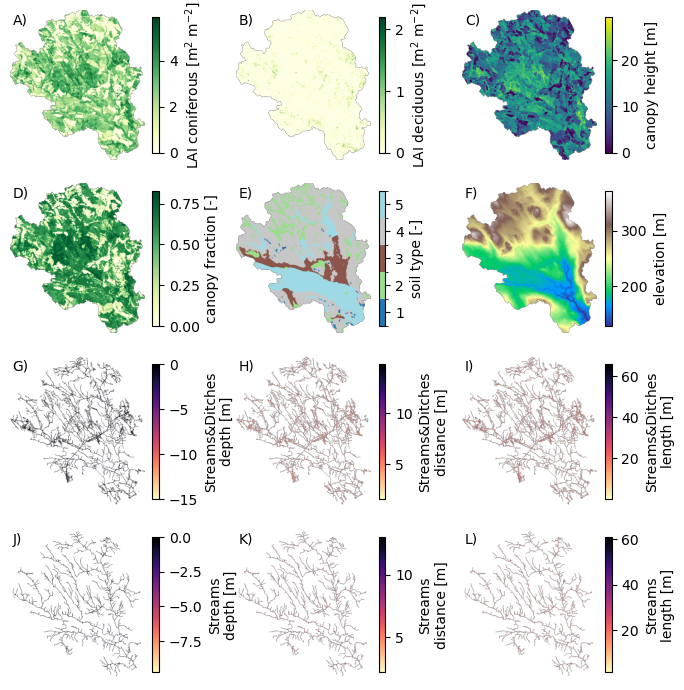

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_20m.png


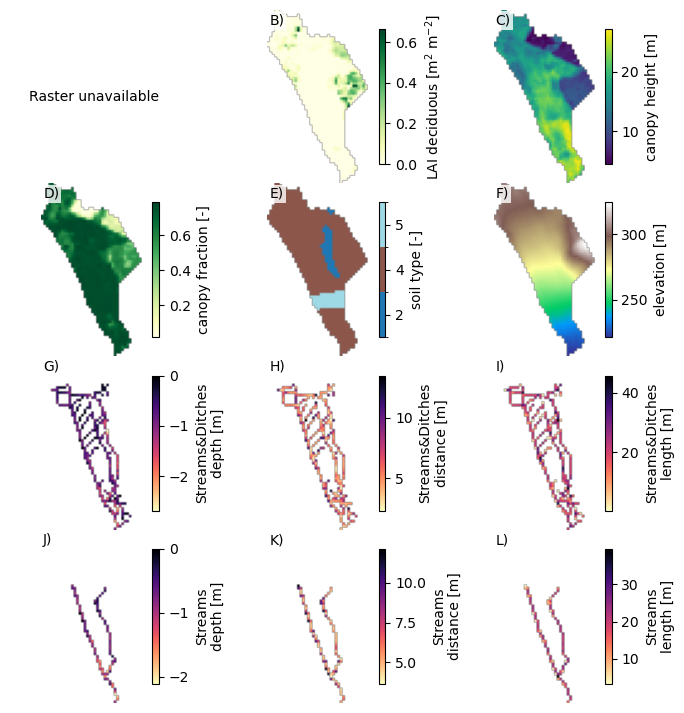

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_20m_C1.png


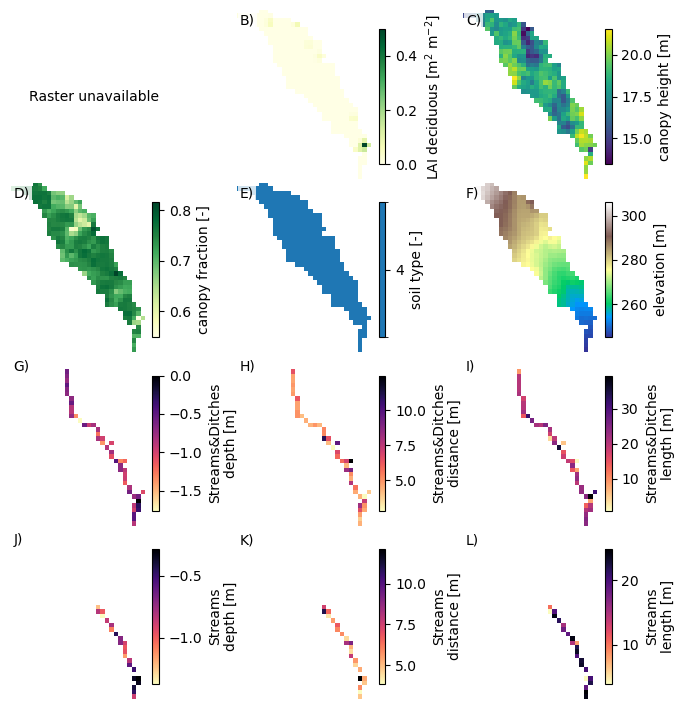

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_20m_C2.png


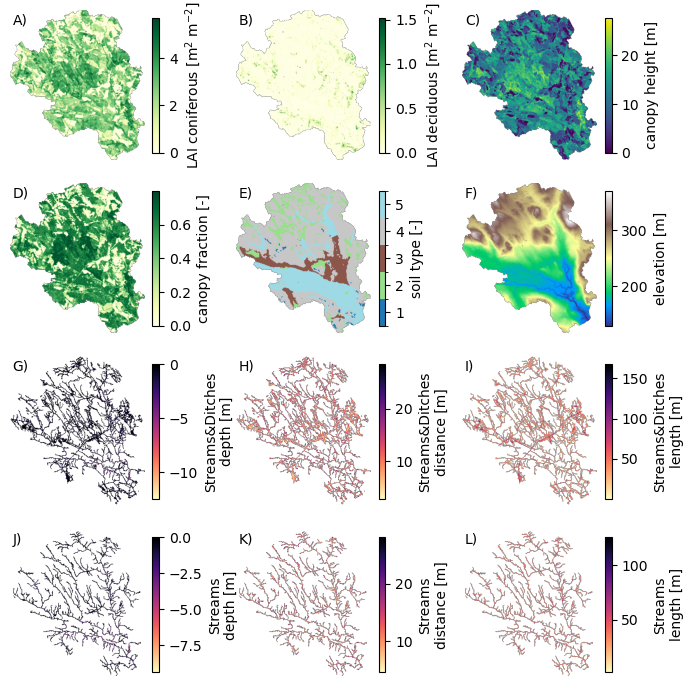

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_40m.png


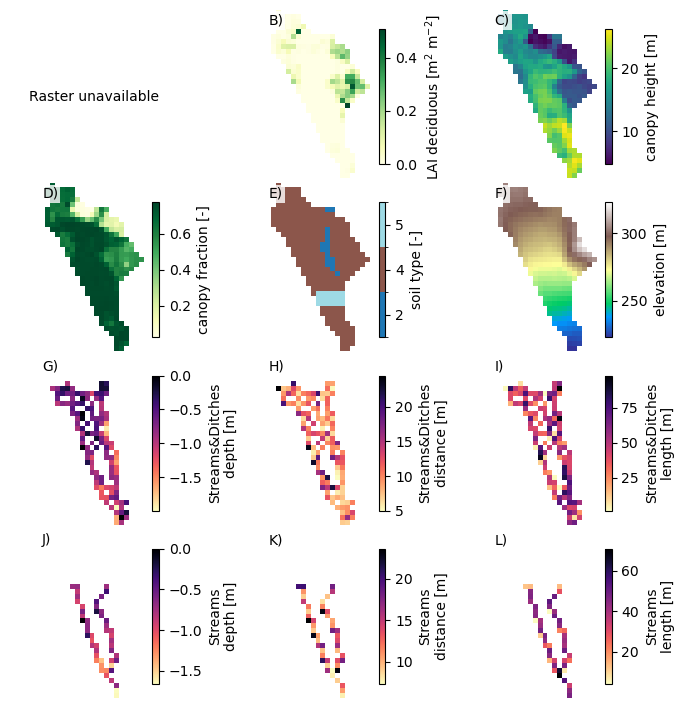

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_40m_C1.png


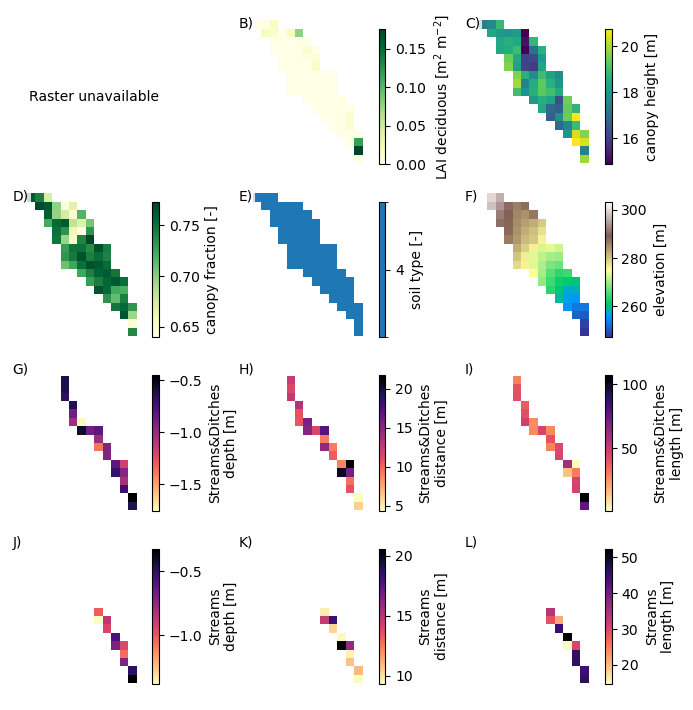

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_40m_C2.png


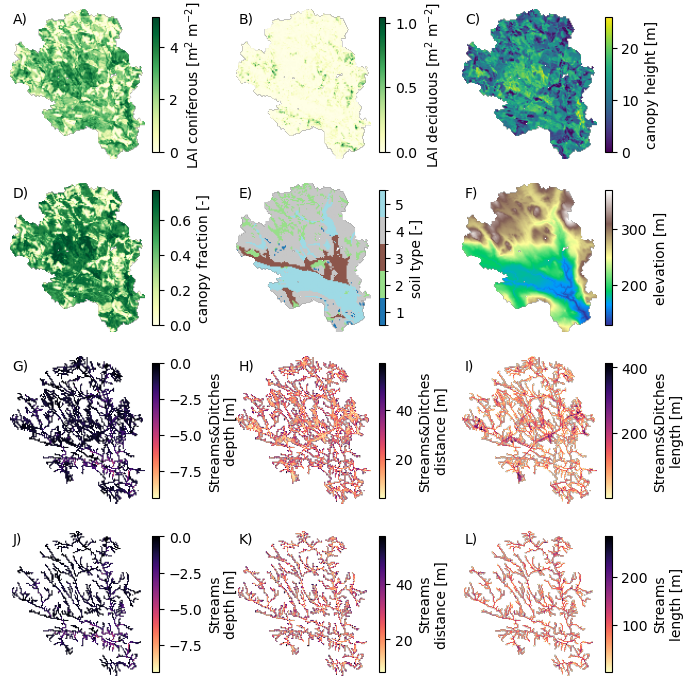

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_80m.png


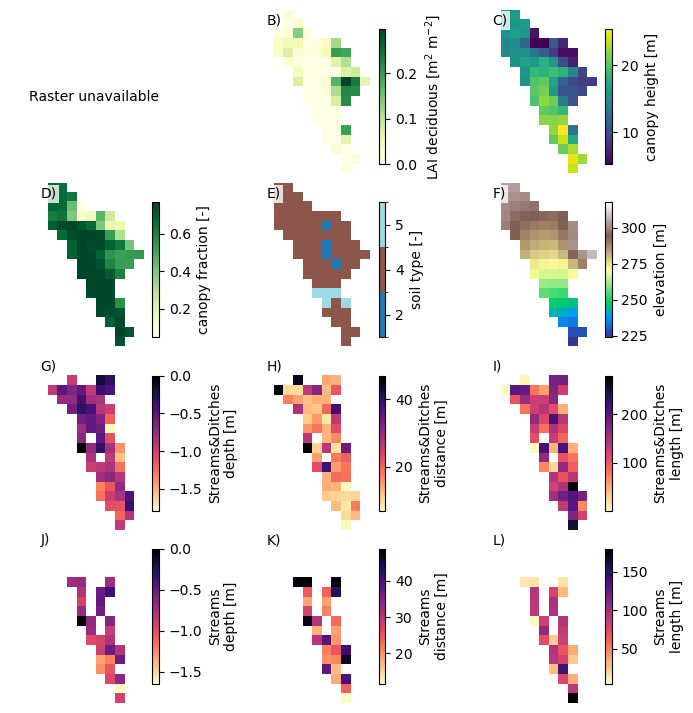

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_80m_C1.png


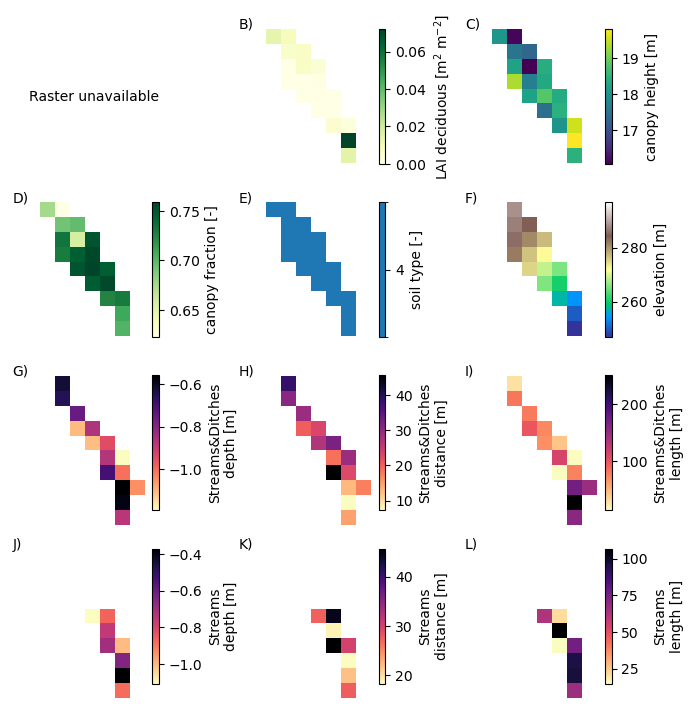

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_80m_C2.png


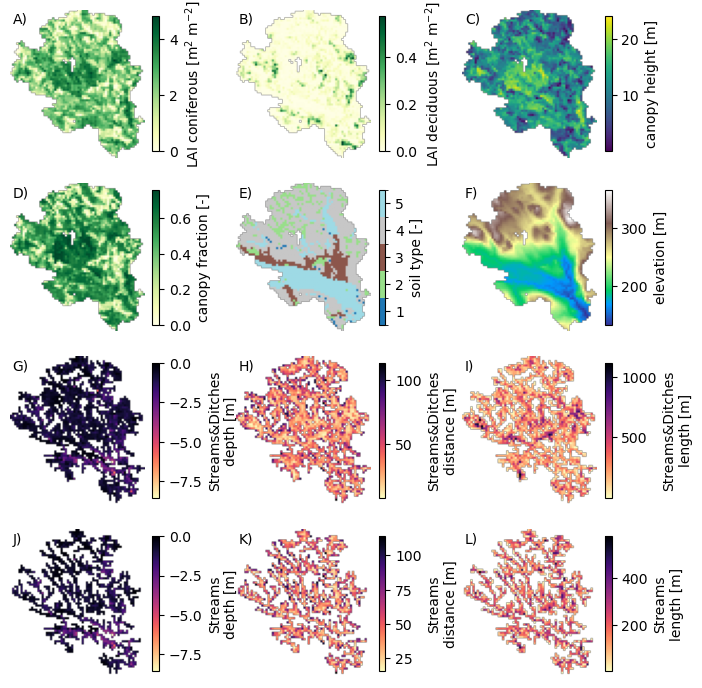

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_160m.png


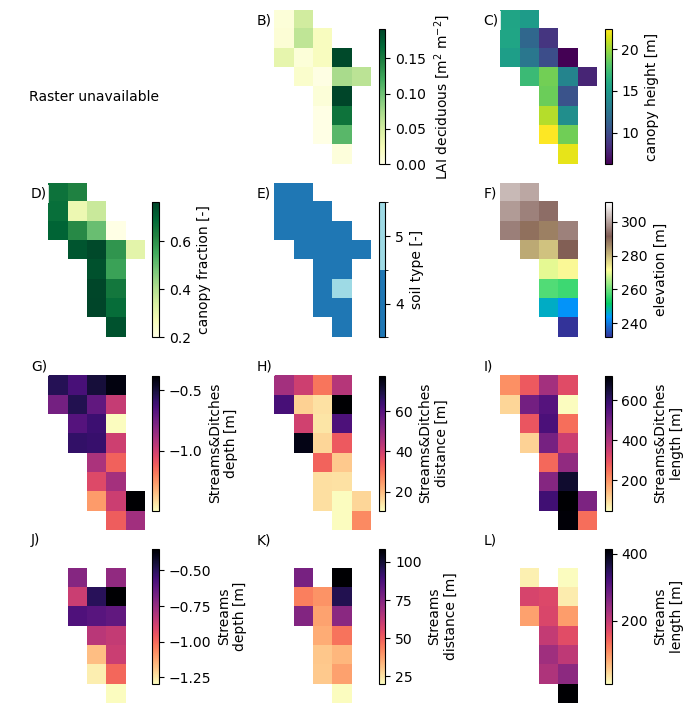

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_160m_C1.png


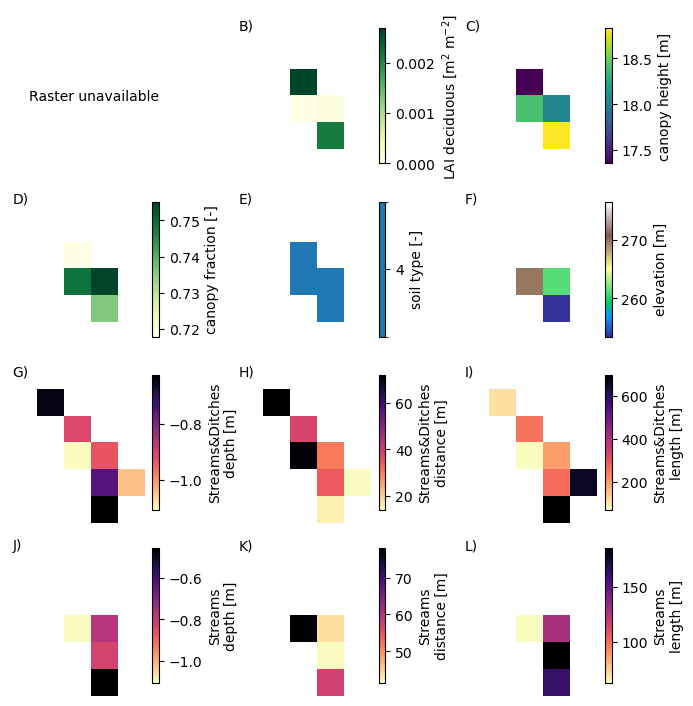

Saved figure: /Users/jpnousu/Data/Krycklan_GIS_data/figs/plot_variables_160m_C2.png


In [2]:
for resolution in resos:
    for catchment in catchs:
        output_path = plot_variables_at_resolution(
            resolution,
            plot_variables,
            figs_dir,
            catchment,
        )
        print(f"Saved figure: {output_path}")